# A5 · Can one learned counterfactual model replace eleven hypothetical branches?

**Complete** · 18,432/18,432 state replays · 108/108 independent trajectories · 2026-11-25T17:43:12+01:00

## What is held fixed?

The regression targets are raw **reconstruction loss decrease** (Skip minus action) and **historical RankMe increase** (action minus Skip). Horizon H specifies the reconstruction target: x0 for H=0 or the mean over the next 1, 4 or 16 same-clip frames. All five predictors see the same outcome labels, same 11 actions, and same A4.1 P5 decision rule. Compare M1 with M2–M4 within a target to isolate future information. Compare H=0 with H=16 at fixed M to examine the separate effect of changing the decision objective.

| Predictor | Decision-time inputs |
|---|---|
| M0 | Selection-bank RankMe, embedding variance, fixed-mask bank loss, changes versus prior state and trailing eight-state average, last committed rates, and candidate action. |
| M1 | M0 plus x0 loss, pixel and embedding summaries. |
| M2 | M1 plus x1 inference summaries. |
| M3 | M2 plus summaries for x1–x4. |
| M4 | M3 plus summaries for x1–x16. |

Each action includes encoder/decoder multipliers and absolute rates; base LR and the target horizon are supplied to every model. Each added image block has mean and spread of per-image losses, pixel mean/spread, embedding mean/spread, mean embedding norm, distance to x0 and between-frame variance. M0 never receives current-image or future metrics. Features use pre-update MAE inference only, with no gradients or candidate updates. A verified frozen encoder implies zero predicted rank change for Skip and decoder-only actions. Skip has zero loss change.

**Supervision and holdout.** For every adaptive A4.1 trajectory, restore the initial checkpoint and AdamW state and replay its committed updates. Match Skip and chosen measurements against the archived labels. All candidate actions, seeds, learning rates and behavior policies for origin clips 1–96 belong to training; clips 97–128 form the forward holdout. There is one capture per origin. No held-out clip contributes to fitting. Test states in A4.1 have earlier policy history, so prospective rollout evaluation uses a second, entirely fresh 128-capture stream. Fits are fixed-recipe multioutput Extra Trees (40 trees, depth 16, minimum 20 examples per leaf). Targets are in seed-specific calibration units during fitting and converted back to raw units for metric reporting. No hyperparameter selection uses the holdout.

**Decision rule.** P5 first seeks a meaningful rank increase without reconstruction degradation. Otherwise it seeks meaningful reconstruction gain without rank degradation. Skip is selected when neither qualifies. Meaningful means above 0.1 A4.1 calibration RMS. For each held-out state the direct reference applies P5 to the measured branch labels, independent of which behavior policy generated that state.

**Deployment.** Direct P5 and M0–M4 each own separate weights and AdamW state for 128 decisions, using both target horizons 0 and 16, three seeds and three base LRs. Learned controllers score actions by CPU regression, perform only the chosen real update, and freeze unselected components. The selected branch is audited afterward; extra pre/post validation assays are excluded from controller timings. Downstream labels are unnecessary.

In [ ]:
import base64, gzip, hashlib, io, json
from pathlib import Path
import numpy as np
from IPython.display import display, Markdown

name="MAE_A5_Learned_Counterfactual_Predictor.ipynb"
locations=(Path.cwd()/name, *(p/"project/cafl4ds/notebooks/selected/mae"/name for p in (Path.cwd(),*Path.cwd().parents)))
path=next(p for p in locations if p.is_file())
meta=json.loads(path.read_text(encoding="utf-8"))["metadata"]["a5"]
def unpack(key):
    raw=base64.b64decode(meta[key],validate=True)
    assert hashlib.sha256(raw).hexdigest()==meta[key+"_sha256"]
    return raw
snapshot=json.loads(gzip.decompress(unpack("snapshot")))
spec,traces=snapshot["spec"],snapshot["traces"]
data=None
if meta["heldout"]:
    with np.load(io.BytesIO(unpack("heldout")),allow_pickle=False) as f: data=dict(f)


In [ ]:
"""Metrics and figures computed only from held-out outcomes and deployment receipts."""
import numpy as np
import matplotlib.pyplot as plt

MODELS=[f"M{k}" for k in range(5)]
ENCODER=np.array([False,False,False,False,True,True,True,True,True,True,True])


def p5(values,threshold=.1):
    """Vectorized P5. Lexicographic tie-break matches A4.1's Pareto filter."""
    l,r=values[:,:,0],values[:,:,1]
    def best(x,other,allowed):
        available=allowed & (x>threshold)
        top=np.where(available,x,-np.inf).max(1,keepdims=True)
        tied=available & (x==top)
        index=np.where(tied,other,-np.inf).argmax(1)
        return np.where(available.any(1),index,0)
    rank=best(r,l,l>=0)
    loss=best(l,r,r>=0)
    action=np.where(rank!=0,rank,loss)
    return action,np.where(rank!=0,"rank",np.where(loss!=0,"loss","skip"))


def metrics(data,model,h=None,lr=None):
    take=np.ones(len(data["h"]),dtype=bool)
    if h is not None:take &= data["h"]==h
    if lr is not None:take &= data["lr"]==lr
    truth=data["truth"][take]; pred=data[model][take];units=data["scales"][take,None,:]
    oracle,_=p5(truth/units);choice,mode=p5(pred/units)
    ix=np.arange(len(choice));chosen=truth[ix,choice]
    active=choice!=0
    violation=((mode=="rank") & (chosen[:,0]<0)) | ((mode=="loss") & (chosen[:,1]<0))
    short=((mode=="rank") & (chosen[:,1]<=.1*units[:,0,1])) | ((mode=="loss") & (chosen[:,0]<=.1*units[:,0,0]))
    t=truth[:,ENCODER,1];v=pred[:,ENCODER,1]
    sign=np.sign(t)==np.sign(v);valid=t!=0
    mean=lambda x:float(x.mean()) if x.size else np.nan
    by_sign=[mean(sign[t>0]),mean(sign[t<0])]
    return dict(states=len(ix),loss_mae=np.abs(truth[:,:,0]-pred[:,:,0]).mean(),rank_mae=np.abs(truth[:,:,1]-pred[:,:,1]).mean(),
                encoder_rank_mae=np.abs(t-v).mean(),sign=mean(sign[valid]),sign_balanced=mean(np.array(by_sign)),
                positive_sign=by_sign[0],negative_sign=by_sign[1],agreement=mean(choice==oracle),skip=mean(~active),
                violations=mean(violation[active]),missed_gain=mean(short[active]),always_skip_agreement=mean(oracle==0),
                selected_loss=mean(chosen[:,0]),selected_rank=mean(chosen[:,1]))


def offline_table(data,lr=None):
    lines=["## Can the predictor choose the direct controller’s action?","",
           "All evaluation clips are held out. Each row compares models predicting the same target. MAEs use raw units over all eleven actions. Rank sign accuracy is restricted to encoder-changing actions with nonzero measured rank change. Balanced sign accuracy averages positive and negative sign recalls. Violation and missed-gain rates use predicted non-Skip decisions as denominator: a violation breaks the guard, while a missed gain fails the meaningful target threshold.","",
           "| Target | Model | Loss MAE | Rank MAE | Encoder rank MAE | Sign | Balanced sign | P5 agreement | Skip | Guard violation | Missed gain |",
           "|---:|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|"]
    for h in (0,16,1,4):
        for m in MODELS:
            v=metrics(data,m,h,lr)
            lines.append(f"| H{h} | {m} | {v['loss_mae']:.5f} | {v['rank_mae']:.5f} | {v['encoder_rank_mae']:.5f} | {v['sign']:.1%} | {v['sign_balanced']:.1%} | {v['agreement']:.1%} | {v['skip']:.1%} | {v['violations']:.1%} | {v['missed_gain']:.1%} |")
    return "\n".join(lines)


def decision_plot(data):
    fig,axes=plt.subplots(1,3,figsize=(12,3.8),layout="constrained")
    for h,color in [(0,"#227080"),(16,"#b35635")]:
        vals=[metrics(data,m,h) for m in MODELS]
        for ax,key,title in zip(axes,["agreement","sign_balanced","violations"],
                ["Action agreement ↑","Balanced rank-sign accuracy ↑","Guard violations among updates ↓"]):
            ax.plot(MODELS,[100*v[key] for v in vals],marker="o",color=color,label=f"Target H={h}")
            ax.set(title=title,ylabel="Percent");ax.grid(axis="y",alpha=.2)
        axes[0].axhline(100*vals[0]["always_skip_agreement"],ls=":",lw=.8,color=color)
    axes[0].legend(fontsize=8,frameon=False);fig.suptitle("Clip-held-out decisions · dotted lines show always-Skip agreement")
    return fig


def context_contrasts(data):
    lines = ["### Does future context help the learned selector?", "",
             "M4 minus M1 on the same held-out states, in percentage points. Intervals are paired 95% bootstrap intervals across the 32 origin clips. Each draw keeps all seeds, actions and policies for a clip together. Violation rates use the active updates selected by each model.", "",
             "| Reconstruction target | P5 agreement difference | Guard violation difference |",
             "|---|---:|---:|"]
    for h in (0, 1, 4, 16):
        take = data["h"] == h
        units = data["scales"][take, None, :]
        truth = data["truth"][take]
        clips, groups = np.unique(data["clip"][take], return_inverse=True)
        draws = np.random.default_rng(715).integers(len(clips), size=(2000, len(clips)))
        oracle, _ = p5(truth / units)
        def summarize(name):
            choice, stage = p5(data[name][take] / units)
            selected = truth[np.arange(len(choice)), choice]
            violation = ((stage == "rank") & (selected[:, 0] < 0)) | ((stage == "loss") & (selected[:, 1] < 0))
            count = lambda v: np.bincount(groups, weights=v, minlength=len(clips))
            totals = np.stack([count(choice == oracle), count(np.ones(len(choice))),
                               count(violation), count(choice != 0)], axis=1)
            samples = np.vstack([totals.sum(axis=0), totals[draws].sum(axis=1)])
            return np.divide(samples[:, [0, 2]], samples[:, [1, 3]],
                             out=np.full((len(samples), 2), np.nan), where=samples[:, [1, 3]] != 0)
        delta = 100 * (summarize("M4") - summarize("M1"))
        lower, upper = np.nanpercentile(delta[1:], [2.5, 97.5], axis=0)
        cells = [f"{delta[0, i]:+.1f} [{lower[i]:+.1f}, {upper[i]:+.1f}]" for i in range(2)]
        lines.append(f"| H{h} | {cells[0]} | {cells[1]} |")
    return "\n".join(lines)


def guard_breakdown(data, traces):
    lines = ["### Which safeguard fails?", "",
             "Each cell gives actual violations / opportunities for that safeguard. In the rank-first stage, a reconstruction loss increase breaks the guard. In the reconstruction fallback, a RankMe decrease breaks it. Prospective counts pool completed trajectories at each horizon across seeds and base learning rates.", "",
             "| Target | Model | Held-out loss guard | Held-out RankMe guard | Continual loss guard | Continual RankMe guard |",
             "|---|---|---:|---:|---:|---:|"]
    def rates(stage, realized):
        values = []
        for name, index in (("rank", 0), ("loss", 1)):
            active = stage == name
            violations = np.count_nonzero(realized[active, index] < 0)
            values.append(f"{violations}/{active.sum()}" if active.any() else "—")
        return values
    for h in (0, 16):
        take = data["h"] == h
        units = data["scales"][take, None, :]
        for model in MODELS:
            choice, stage = p5(data[model][take] / units)
            realized = data["truth"][take][np.arange(len(choice)), choice]
            counts = rates(stage, realized)
            steps = [s for r in traces if r["h"] == h and r["arm"] == model for s in r["steps"]]
            if steps:
                counts.extend(rates(np.array([s["stage"] for s in steps]), np.array([s["actual"] for s in steps])))
            else:
                counts.extend(["—", "—"])
            lines.append("| " + " | ".join([f"H{h}", model, *counts]) + " |")
    return "\n".join(lines)


def deployed(spec,traces,lr=.001):
    def avg(x):return float(np.mean(x)) if len(x) else np.nan
    lines=["### Independent continual trajectories","",f"Base LR {lr:g}. Final reconstruction change compares the same 128 origin images at steps 0 and 128 with fixed masks. RankMe uses the independent historical audit bank. Timing includes decision features, selection and commitment. The direct A4.1 implementation retains its candidate copies concurrently and verifies frozen parameters and optimizer state. These choices affect its runtime and peak memory. External audits and I/O are excluded. Memory is peak additional allocated CUDA memory per decision; model CPU buffers are reported separately.","",
           "| Target | Controller | Seeds | Final loss Δ | Final rank Δ | Skip | Guard violation | Median ms | P95 ms | Peak GPU MiB |","|---:|---|---:|---:|---:|---:|---:|---:|---:|---:|"]
    for h in (0,16):
        for arm in ["direct",*MODELS]:
            runs=[r for r in traces if r["h"]==h and r["lr"]==lr and r["arm"]==arm]
            if not runs:continue
            steps=[s for r in runs for s in r["steps"]]
            losses=avg([np.mean(np.subtract(r["cohorts"]["128"],r["cohorts"]["0"])) for r in runs])
            ranks=avg([r["steps"][-1]["audit_rank"]-r["initial_rank"] for r in runs])
            viol=[s["actual"][0 if s["stage"]=="rank" else 1]<0 for s in steps if s["action"]!=0]
            times=[s["seconds"]*1000 for s in steps]
            lines.append(f"| {h} | {arm} | {len(runs)} | {losses:+.5f} | {ranks:+.4f} | {avg([s['action']==0 for s in steps]):.1%} | {avg(viol):.1%} | {np.median(times):.2f} | {np.percentile(times,95):.2f} | {max(s['extra_gpu_bytes'] for s in steps)/2**20:.1f} |")
    return "\n".join(lines)


def curves(traces,lr=.001,h=16):
    fig,axes=plt.subplots(1,2,figsize=(11,3.9),layout="constrained")
    for arm in ["direct",*MODELS]:
        runs=[r for r in traces if r["h"]==h and r["lr"]==lr and r["arm"]==arm]
        if not runs:continue
        ranks=[[r["initial_rank"],*[s["audit_rank"] for s in r["steps"]]] for r in runs]
        losses=[[np.mean(r["cohorts"][str(i)]) for i in range(0,129,16)] for r in runs]
        axes[0].plot(np.mean(ranks,axis=0),label=f"{arm} ({len(runs)})")
        axes[1].plot(range(0,129,16),np.mean(losses,axis=0),marker=".",label=arm)
    for ax,title in zip(axes,["Independent historical audit RankMe","Fixed origin-image cohort loss"]):
        ax.set(xlabel="Committed decisions",title=title); ax.grid(axis="y",alpha=.2)
    axes[0].legend(fontsize=8,frameon=False);fig.suptitle(f"Continual controllers · H={h}, base LR={lr:g}")
    return fig


def direct_horizon_contrast(traces):
    lines = ["### Does changing the direct controller’s reconstruction target help?", "",
             "Paired differences compare the direct H16 controller with direct H0 from the same checkpoint, base LR and fresh stream. A negative loss difference favors H16. A positive RankMe difference favors H16. Only seeds with both finished trajectories enter a row.", "",
             "| Base LR | Paired seeds | Final cohort loss, H16 − H0 | Final audit RankMe, H16 − H0 |",
             "|---:|---:|---:|---:|"]
    runs = {(r["lr"], r["seed"], r["h"]): r for r in traces if r["arm"] == "direct"}
    for lr in sorted({key[0] for key in runs}):
        differences = []
        for rate, seed, h in runs:
            if rate != lr or h != 0 or (lr, seed, 16) not in runs:
                continue
            base, future = runs[lr, seed, 0], runs[lr, seed, 16]
            differences.append([np.mean(np.subtract(future["cohorts"]["128"], base["cohorts"]["128"])),
                                future["steps"][-1]["audit_rank"] - base["steps"][-1]["audit_rank"]])
        if differences:
            loss, rank = np.mean(differences, axis=0)
            lines.append(f"| {lr:g} | {len(differences)} | {loss:+.5f} | {rank:+.4f} |")
    return "\n".join(lines)


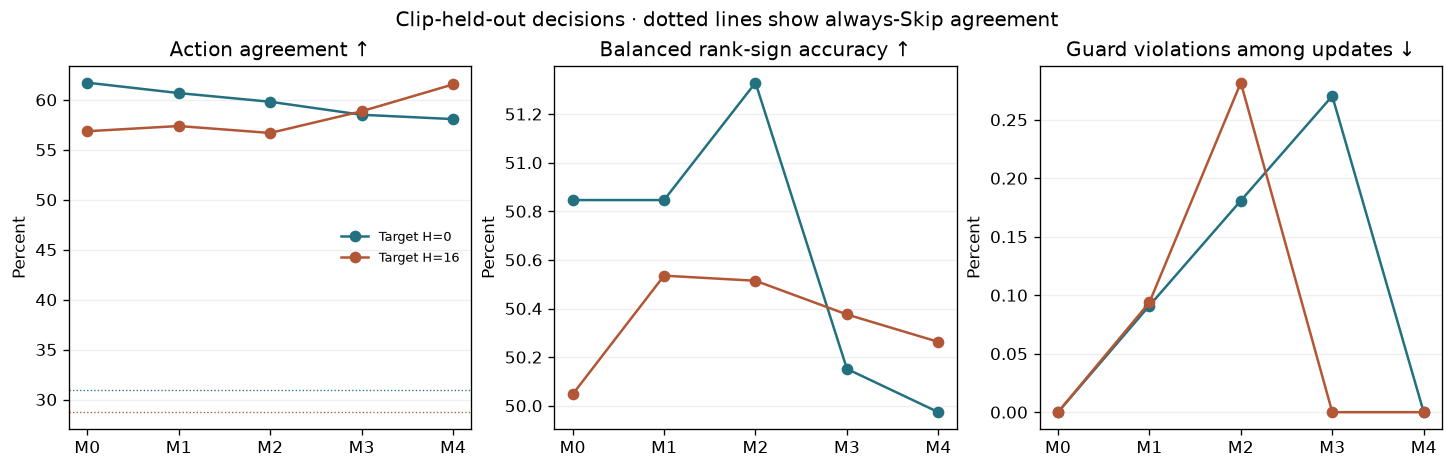

In [ ]:
decision_plot(data); plt.show()

In [ ]:
display(Markdown(offline_table(data)))

## Can the predictor choose the direct controller’s action?

All evaluation clips are held out. Each row compares models predicting the same target. MAEs use raw units over all eleven actions. Rank sign accuracy is restricted to encoder-changing actions with nonzero measured rank change. Balanced sign accuracy averages positive and negative sign recalls. Violation and missed-gain rates use predicted non-Skip decisions as denominator: a violation breaks the guard, while a missed gain fails the meaningful target threshold.

| Target | Model | Loss MAE | Rank MAE | Encoder rank MAE | Sign | Balanced sign | P5 agreement | Skip | Guard violation | Missed gain |
|---:|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| H0 | M0 | 0.01690 | 0.09373 | 0.14729 | 93.3% | 50.8% | 61.7% | 3.1% | 0.0% | 30.9% |
| H0 | M1 | 0.01186 | 0.08745 | 0.13743 | 93.3% | 50.8% | 60.7% | 4.7% | 0.1% | 30.9% |
| H0 | M2 | 0.01215 | 0.08644 | 0.13584 | 93.4% | 51.3% | 59.8% | 4.0% | 0.2% | 31.4% |
| H0 | M3 | 0.01211 | 0.08682 | 0.13643 | 93.1% | 50.2% | 58.5% | 3.6% | 0.3% | 31.0% |
| H0 | M4 | 0.01157 | 0.08616 | 0.13539 | 93.3% | 50.0% | 58.1% | 6.8% | 0.0% | 31.2% |
| H16 | M0 | 0.00979 | 0.07255 | 0.11401 | 88.5% | 50.0% | 56.9% | 4.8% | 0.0% | 30.5% |
| H16 | M1 | 0.00862 | 0.07857 | 0.12347 | 88.5% | 50.5% | 57.4% | 7.5% | 0.1% | 30.8% |
| H16 | M2 | 0.00874 | 0.07948 | 0.12490 | 88.4% | 50.5% | 56.7% | 7.6% | 0.3% | 31.9% |
| H16 | M3 | 0.00843 | 0.08167 | 0.12833 | 88.5% | 50.4% | 58.9% | 8.4% | 0.0% | 30.0% |
| H16 | M4 | 0.00833 | 0.08106 | 0.12738 | 88.6% | 50.3% | 61.5% | 9.5% | 0.0% | 28.5% |
| H1 | M0 | 0.01541 | 0.06537 | 0.10273 | 90.9% | 51.2% | 60.2% | 1.1% | 0.0% | 32.6% |
| H1 | M1 | 0.01279 | 0.06471 | 0.10169 | 90.9% | 51.8% | 58.3% | 5.1% | 0.1% | 31.6% |
| H1 | M2 | 0.01275 | 0.06620 | 0.10403 | 90.9% | 51.0% | 58.8% | 5.9% | 0.0% | 31.6% |
| H1 | M3 | 0.01269 | 0.06837 | 0.10744 | 90.6% | 50.6% | 58.7% | 4.6% | 0.4% | 31.3% |
| H1 | M4 | 0.01245 | 0.07037 | 0.11058 | 90.7% | 50.1% | 60.7% | 8.5% | 0.1% | 29.8% |
| H4 | M0 | 0.01091 | 0.06913 | 0.10864 | 92.1% | 50.4% | 56.9% | 2.5% | 0.0% | 38.1% |
| H4 | M1 | 0.01009 | 0.07518 | 0.11814 | 91.9% | 50.4% | 54.9% | 6.3% | 0.2% | 37.1% |
| H4 | M2 | 0.01046 | 0.07653 | 0.12027 | 92.0% | 50.5% | 56.2% | 6.6% | 0.0% | 36.8% |
| H4 | M3 | 0.00993 | 0.07949 | 0.12491 | 91.9% | 50.3% | 56.0% | 6.7% | 0.3% | 36.6% |
| H4 | M4 | 0.00959 | 0.07941 | 0.12479 | 92.1% | 50.1% | 59.6% | 9.6% | 0.0% | 35.4% |

In [ ]:
display(Markdown(context_contrasts(data)))

### Does future context help the learned selector?

M4 minus M1 on the same held-out states, in percentage points. Intervals are paired 95% bootstrap intervals across the 32 origin clips. Each draw keeps all seeds, actions and policies for a clip together. Violation rates use the active updates selected by each model.

| Reconstruction target | P5 agreement difference | Guard violation difference |
|---|---:|---:|
| H0 | -2.6 [-4.9, -0.3] | -0.1 [-0.3, +0.0] |
| H1 | +2.3 [-0.1, +4.9] | +0.0 [+0.0, +0.0] |
| H4 | +4.8 [+3.0, +6.9] | -0.2 [-0.6, +0.0] |
| H16 | +4.2 [+1.4, +7.1] | -0.1 [-0.3, +0.0] |

In [ ]:
display(Markdown(guard_breakdown(data,traces)))

### Which safeguard fails?

Each cell gives actual violations / opportunities for that safeguard. In the rank-first stage, a reconstruction loss increase breaks the guard. In the reconstruction fallback, a RankMe decrease breaks it. Prospective counts pool completed trajectories at each horizon across seeds and base learning rates.

| Target | Model | Held-out loss guard | Held-out RankMe guard | Continual loss guard | Continual RankMe guard |
|---|---|---:|---:|---:|---:|
| H0 | M0 | — | 0/1116 | — | 0/1152 |
| H0 | M1 | — | 1/1098 | — | 3/1152 |
| H0 | M2 | — | 2/1106 | — | 0/1152 |
| H0 | M3 | — | 3/1110 | — | 1/1152 |
| H0 | M4 | — | 0/1074 | — | 0/1152 |
| H16 | M0 | — | 0/1097 | — | 1/1152 |
| H16 | M1 | — | 1/1066 | — | 3/1152 |
| H16 | M2 | — | 3/1065 | — | 0/1152 |
| H16 | M3 | — | 0/1055 | — | 1/1152 |
| H16 | M4 | — | 0/1043 | — | 0/1152 |

**Predictor CPU memory.** Fitted tree node and value buffers occupy M0: 13.83 MiB, M1: 14.01 MiB, M2: 13.54 MiB, M3: 12.72 MiB, M4: 13.43 MiB. GPU figures in the continual table measure incremental CUDA allocations. Host Python overhead and raw image decoding are outside these measures.

In [ ]:
display(Markdown(direct_horizon_contrast(traces)))

### Does changing the direct controller’s reconstruction target help?

Paired differences compare the direct H16 controller with direct H0 from the same checkpoint, base LR and fresh stream. A negative loss difference favors H16. A positive RankMe difference favors H16. Only seeds with both finished trajectories enter a row.

| Base LR | Paired seeds | Final cohort loss, H16 − H0 | Final audit RankMe, H16 − H0 |
|---:|---:|---:|---:|
| 0.0003 | 3 | +0.03128 | -0.2290 |
| 0.001 | 3 | -0.00110 | -0.0465 |
| 0.003 | 3 | -0.01300 | +0.1256 |

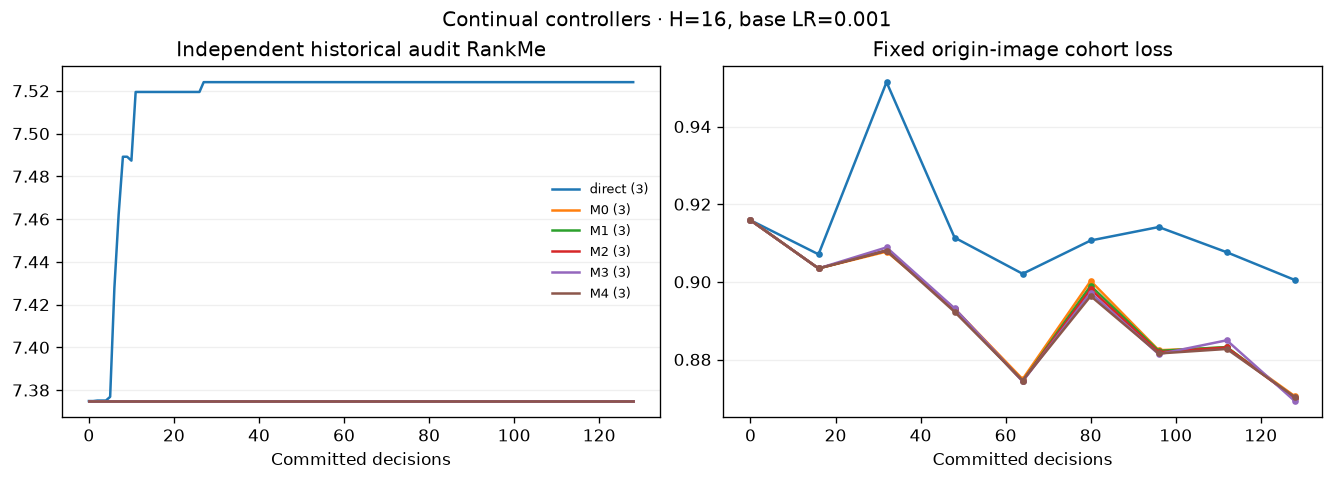

In [ ]:
curves(traces,lr=0.001,h=16); plt.show()

In [ ]:
display(Markdown(deployed(spec,traces,lr=0.001)))

### Independent continual trajectories

Base LR 0.001. Final reconstruction change compares the same 128 origin images at steps 0 and 128 with fixed masks. RankMe uses the independent historical audit bank. Timing includes decision features, selection and commitment. The direct A4.1 implementation retains its candidate copies concurrently and verifies frozen parameters and optimizer state. These choices affect its runtime and peak memory. External audits and I/O are excluded. Memory is peak additional allocated CUDA memory per decision; model CPU buffers are reported separately.

| Target | Controller | Seeds | Final loss Δ | Final rank Δ | Skip | Guard violation | Median ms | P95 ms | Peak GPU MiB |
|---:|---|---:|---:|---:|---:|---:|---:|---:|---:|
| 0 | direct | 3 | -0.01429 | +0.1957 | 25.5% | 0.0% | 404.28 | 467.57 | 55.9 |
| 0 | M0 | 3 | -0.04531 | +0.0000 | 0.0% | 0.0% | 18.51 | 23.78 | 24.2 |
| 0 | M1 | 3 | -0.04571 | +0.0000 | 0.0% | 0.0% | 23.83 | 32.38 | 24.2 |
| 0 | M2 | 3 | -0.04579 | +0.0000 | 0.0% | 0.0% | 28.56 | 36.16 | 24.2 |
| 0 | M3 | 3 | -0.04661 | +0.0000 | 0.0% | 0.0% | 29.73 | 36.66 | 24.2 |
| 0 | M4 | 3 | -0.04574 | +0.0000 | 0.0% | 0.0% | 30.62 | 39.55 | 24.2 |
| 16 | direct | 3 | -0.01539 | +0.1492 | 34.9% | 0.0% | 405.81 | 463.29 | 23.1 |
| 16 | M0 | 3 | -0.04531 | +0.0000 | 0.0% | 0.0% | 18.50 | 23.73 | 24.2 |
| 16 | M1 | 3 | -0.04571 | +0.0000 | 0.0% | 0.0% | 23.64 | 32.41 | 24.2 |
| 16 | M2 | 3 | -0.04579 | +0.0000 | 0.0% | 0.0% | 28.90 | 37.19 | 24.2 |
| 16 | M3 | 3 | -0.04657 | +0.0000 | 0.0% | 0.0% | 29.63 | 41.21 | 24.2 |
| 16 | M4 | 3 | -0.04553 | +0.0000 | 0.0% | 0.0% | 30.67 | 37.68 | 24.2 |

In [ ]:
display(Markdown(deployed(spec,traces,lr=0.003)))

### Independent continual trajectories

Base LR 0.003. Final reconstruction change compares the same 128 origin images at steps 0 and 128 with fixed masks. RankMe uses the independent historical audit bank. Timing includes decision features, selection and commitment. The direct A4.1 implementation retains its candidate copies concurrently and verifies frozen parameters and optimizer state. These choices affect its runtime and peak memory. External audits and I/O are excluded. Memory is peak additional allocated CUDA memory per decision; model CPU buffers are reported separately.

| Target | Controller | Seeds | Final loss Δ | Final rank Δ | Skip | Guard violation | Median ms | P95 ms | Peak GPU MiB |
|---:|---|---:|---:|---:|---:|---:|---:|---:|---:|
| 0 | direct | 3 | +0.01422 | +0.1125 | 31.0% | 0.0% | 405.97 | 473.63 | 23.9 |
| 0 | M0 | 3 | -0.02281 | +0.0000 | 0.0% | 0.0% | 18.49 | 24.38 | 24.2 |
| 0 | M1 | 3 | -0.02477 | +0.0000 | 0.0% | 0.0% | 23.76 | 32.12 | 24.2 |
| 0 | M2 | 3 | -0.02383 | +0.0000 | 0.0% | 0.0% | 28.59 | 37.48 | 24.2 |
| 0 | M3 | 3 | -0.02260 | +0.0000 | 0.0% | 0.0% | 29.71 | 40.13 | 24.2 |
| 0 | M4 | 3 | -0.02873 | +0.0000 | 0.0% | 0.0% | 30.70 | 40.50 | 24.2 |
| 16 | direct | 3 | +0.00122 | +0.2381 | 33.1% | 0.0% | 403.56 | 463.43 | 23.1 |
| 16 | M0 | 3 | -0.02477 | +0.0000 | 0.0% | 0.0% | 18.52 | 24.20 | 24.2 |
| 16 | M1 | 3 | -0.02460 | +0.0000 | 0.0% | 0.0% | 23.57 | 30.82 | 24.2 |
| 16 | M2 | 3 | -0.02358 | +0.0000 | 0.0% | 0.0% | 28.63 | 37.26 | 24.2 |
| 16 | M3 | 3 | -0.01383 | +0.0000 | 0.0% | 0.0% | 29.74 | 37.58 | 24.2 |
| 16 | M4 | 3 | -0.02429 | +0.0000 | 0.0% | 0.0% | 30.81 | 40.45 | 24.2 |

In [ ]:
display(Markdown(deployed(spec,traces,lr=0.0003)))

### Independent continual trajectories

Base LR 0.0003. Final reconstruction change compares the same 128 origin images at steps 0 and 128 with fixed masks. RankMe uses the independent historical audit bank. Timing includes decision features, selection and commitment. The direct A4.1 implementation retains its candidate copies concurrently and verifies frozen parameters and optimizer state. These choices affect its runtime and peak memory. External audits and I/O are excluded. Memory is peak additional allocated CUDA memory per decision; model CPU buffers are reported separately.

| Target | Controller | Seeds | Final loss Δ | Final rank Δ | Skip | Guard violation | Median ms | P95 ms | Peak GPU MiB |
|---:|---|---:|---:|---:|---:|---:|---:|---:|---:|
| 0 | direct | 3 | -0.03208 | +0.8280 | 36.7% | 0.0% | 413.68 | 511.01 | 23.9 |
| 0 | M0 | 3 | -0.05401 | +0.0000 | 0.0% | 0.0% | 19.43 | 28.36 | 24.2 |
| 0 | M1 | 3 | -0.05404 | -0.0549 | 0.0% | 0.8% | 24.10 | 34.22 | 24.2 |
| 0 | M2 | 3 | -0.05401 | +0.0000 | 0.0% | 0.0% | 30.01 | 59.69 | 24.2 |
| 0 | M3 | 3 | -0.05419 | -0.0287 | 0.0% | 0.3% | 30.74 | 38.84 | 24.2 |
| 0 | M4 | 3 | -0.05399 | +0.0000 | 0.0% | 0.0% | 31.43 | 40.47 | 24.2 |
| 16 | direct | 3 | -0.00080 | +0.5990 | 52.9% | 0.0% | 413.31 | 491.64 | 23.1 |
| 16 | M0 | 3 | -0.05405 | -0.0337 | 0.0% | 0.3% | 19.29 | 25.32 | 24.2 |
| 16 | M1 | 3 | -0.05404 | -0.0549 | 0.0% | 0.8% | 25.04 | 34.23 | 24.2 |
| 16 | M2 | 3 | -0.05401 | +0.0000 | 0.0% | 0.0% | 29.78 | 37.34 | 24.2 |
| 16 | M3 | 3 | -0.05419 | -0.0287 | 0.0% | 0.3% | 31.29 | 39.42 | 24.2 |
| 16 | M4 | 3 | -0.05403 | +0.0000 | 0.0% | 0.0% | 31.93 | 45.68 | 24.2 |

## Inspect the underlying measurements

Run All to recalculate the tables and plots offline using the raw held-out effects, predictions, scale factors and rollout receipts embedded in notebook metadata. Input image caches and original checkpoints are needed only to replay, retrain or collect new outcomes.

In [ ]:
if data is not None:
    print("Held-out states:", len(data["clip"]), "distinct clip indices:", np.unique(data["clip"]))
    print(metrics(data,"M4",h=0,lr=.001))
if traces:
    display(traces[0]["steps"][0])
print(list(snapshot["source"]))